In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import os

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src import setup_workspace, query_to_df, ds3on1

# 1. Inicializar workspace y rutas
paths = setup_workspace()

# 2. Consultar directamente a PostgreSQL (vía DuckDB ATTACH)
#df = query_to_df("SELECT * FROM db.surveys;")

# 3. Análisis univariable 3-en-1
#ds3on1(df, 'happy', Desc=True, Stat=True, Graph=True)

✅ Workspace anclado en: /home/josu/Documentos/DataScienceCourse
📂 Ruta de tablas verificada: /home/josu/Documentos/DataScienceCourse/data/raw/Tables


🟢 < Module 8.1 > Feature Engineering, PCA & Calibrated Resampling (SMOTE):
##### 🎯 Context & Objectives

Data cannot be fed into a Machine Learning model exactly as it comes out of an Exploratory Data Analysis. In this module, you will finalize the feature matrix by applying deterministic transformations (replacing any stochastic binning to ensure reproducibility), reducing dimensionality for highly correlated blocks, and preparing the mathematical groundwork for handling imbalanced classes using **SMOTE** (Synthetic Minority Over-sampling Technique). A critical objective is to understand **when** and **how** to apply SMOTE without causing _data leakage_ or generating mathematically impossible synthetic records (like continuous decimals for categorical countries).

##### 📑 Exercise Instructions

###### 1. Syntactic / Algorithmic Level (Feature Engineering & Transformation)

Create a Python notebook (`notebooks/08_1_feature_engineering_resampling.ipynb`) that implements the following steps on your cleaned dataset:

- **Deterministic Thresholding (Fixing Stochastic Binning):**
    
    - Review any custom binning functions you planned to use (e.g., separating `happy` or `lrscale` into binary classes). If you previously used stochastic or weighted random approaches (like a custom `BinarizePond` function), replace them with **strict, deterministic threshold rules** (e.g., `value >= median` or `value >= 7`). Document why introducing randomness when constructing a target variable reduces the theoretical maximum achievable accuracy (Label Noise).
        
- **Dimensionality Reduction (The Institutional Trust Block):**
    
    - In Module 7, you discovered that `trstprl` (trust in parliament) and `trstlgl` (trust in the legal system) are highly correlated (ρ = 0.628).
        
    - Implement **PCA (Principal Component Analysis)** with `n_components=1` (using `sklearn.decomposition.PCA`) on these two variables to create a single `institutional_trust_index`. Briefly compare the explained variance of this component versus calculating a simple arithmetic mean.
        
- **Categorical Encoding:**
    
    - Apply `pd.get_dummies(drop_first=True)` to your nominal variables (e.g., macro-regions) to prevent perfect multicollinearity in linear models, as agreed upon during the EDA phase.
        

###### 2. Applied / Data Level (Calibrated Resampling with SMOTE)

Imbalanced classes require resampling, but executing it at the wrong time ruins the validity of the experiment.

- **The Golden Rule of Resampling:**
    
    - Define a function that accepts `X_train` and `y_train` and applies `imblearn.over_sampling.SMOTE` to balance the target classes.
        
    - **Crucial Conceptual Task:** Explain in your notebook why SMOTE must **never** be applied to the entire dataset before making the validation split. What happens to the test set and the _data leakage_ if you oversample before splitting?
        
- **Auditing Synthetic Generation (The Substrate Bias):**
    
    - Generate a test `X_train_resampled` by applying your SMOTE function.
        
    - Analyze the generated synthetic rows. Since SMOTE interpolates mathematically (calculating Euclidean distances) between neighboring points, what happens to discrete or ordinal variables (like the ISCED educational level or an economic cluster `0, 1, 2`)? Do they become continuous decimals (e.g., `cluster = 1.45`)?
        
    - Apply a post-processing function (iterative rounding) to the synthetic data to force these features back into valid discrete values.
        

##### 🌐 Official References & Documentation

- **Imbalanced-Learn (SMOTE):** [SMOTE Documentation](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html)
    
- **Scikit-Learn PCA:** [PCA Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
    

##### 📚 Recommended Manuals & CheatSheets

- **Handling Imbalanced Datasets:** [SMOTE for Imbalanced Classification with Python](https://machinelearningmastery.com/smote-oversampling-for-imbalanced-classification/)
    
- **Feature Engineering:** _Feature Engineering for Machine Learning (Alice Zheng & Amanda Casari)_ — Dimensionality Reduction.
    

💻 **Your Challenge:** Create the notebook `notebooks/08_1_feature_engineering_resampling.ipynb`. Implement deterministic binning, extract the institutional trust PCA index, configure the SMOTE function (with rounding logic for ordinal values), and draft the explanation of why SMOTE is strictly a _post-split_ operation. Share your code when ready! 🚀📊


In [3]:
# Step 1: Prepare the dataset with the target variables to work on. (lrscale,happy ,trstprl , trstlgl, cntry)
df81 = query_to_df("SELECT lrscale, happy, trstprl, trstlgl, cntry  FROM db.surveys WHERE COLUMNS (*) IS NOT NULL")
# You can check the function on ./src/db.py
df81.head(6)

,lrscale,happy,trstprl,trstlgl,cntry
0,3,7,2,2,GR
1,8,5,1,4,IT
2,5,6,6,3,BE
3,5,8,0,4,HU
4,3,6,1,3,GR
5,5,10,7,8,RS


In [5]:
# Step 1.1, first of all we declare  our functions non respondent values and hot-deck imputation after applying smote on train group, preventing the data leekage on test group.
# Our future model will have to train with the synthetic minority clases train group, assigning properly the variables for avoid data leekage.

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE

# 0. Global reproducibility seed
SEED = 42

# 1. Declare deterministic cleaning & row-level counter function (no randomness)
def clean_and_count(df: pd.DataFrame):
    df = df.copy()
    df["n_nonresp"] = 0
    CODE_GROUPS = [
        [99999, 88888, 77777, 66666],
        [9999,  8888,  7777,  6666],
        [999,   888,   777,   666],
        [99,    88,    77,    66],
    ]
    for col in df.columns:
        if col == "n_nonresp" or not pd.api.types.is_numeric_dtype(df[col]):
            continue
        unique = set(df[col].dropna().unique())
        codes_found = next(([c for c in g if c in unique] for g in CODE_GROUPS if any(c in unique for c in g)), None)
        if codes_found:
            mask = df[col].isin(codes_found)
            df.loc[mask, "n_nonresp"] += 1
            df.loc[mask, col] = np.nan
    df["has_nonresp"] = (df["n_nonresp"] > 0).astype(int)
    return df

# 2. Declare asymmetric Hot-deck imputation using isolated Generator (PCG64)[cite: 7]
def hot_deck_impute_split(X_train: pd.DataFrame, X_test: pd.DataFrame, seed: int = SEED):
    rng = np.random.default_rng(seed)
    X_tr, X_te = X_train.copy(), X_test.copy()
    protected = {"n_nonresp", "has_nonresp"}

    for col in X_tr.columns:
        if col in protected or not pd.api.types.is_numeric_dtype(X_tr[col]):
            continue
        valid_tr = X_tr[col].dropna()
        if valid_tr.empty:
            continue
        weights = valid_tr.value_counts(normalize=True)
        cats, probs = weights.index.to_numpy(), weights.to_numpy()

        mask_tr, mask_te = X_tr[col].isna(), X_te[col].isna()
        if mask_tr.any():
            X_tr.loc[mask_tr, col] = rng.choice(cats, size=int(mask_tr.sum()), p=probs)
        if mask_te.any():
            X_te.loc[mask_te, col] = rng.choice(cats, size=int(mask_te.sum()), p=probs)

    return X_tr, X_te

In [6]:
# Step 1.2,After non respondent cleaning, we must create or dummy target variable , in our  case we will create happy_high, every row with happy == 7 or higher will be 1 in this variable,
# also we will delete from the split train/test happy variable to avoid data leekage.
df81c = clean_and_count(df81)
df81c.info()

<class 'pandas.DataFrame'>
RangeIndex: 37499 entries, 0 to 37498
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   lrscale      33057 non-null  float64
 1   happy        37389 non-null  float64
 2   trstprl      36805 non-null  float64
 3   trstlgl      36843 non-null  float64
 4   cntry        37499 non-null  str    
 5   n_nonresp    37499 non-null  int64  
 6   has_nonresp  37499 non-null  int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 2.1 MB


In [7]:
# Step 1.2, dummy creation ['happy_high'] (0-1, No-Yes)
df81c['happy_high']=(df81c['happy'] >= 7).astype(int)
df81c['happy_high'].describe()

count    37499.000000
mean         0.761647
std          0.426082
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: happy_high, dtype: float64

In [8]:
del df81

In [9]:
# Step 1.2, Lets declare the variable groups for a clean split train/test function.

groups= df81c["cntry"]
X= df81c[["lrscale", "trstprl", "trstlgl", "n_nonresp", "has_nonresp"]].copy()
y= df81c["happy_high"].copy()

In [11]:
# Step 1.2, before dimensionality reduction and artifically sampled by smote our train group, we will have to hot-deck impute on our X train test  data, filling NAN values
# Group train/test split by country
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

# Anti-leakage Hot-deck imputation (fit weights on X_train, fill both), calling our second function.
X_train_imp, X_test_imp, = hot_deck_impute_split(X_train, X_test, seed=42)

In [12]:
# Step 1.3: Apply PCA (Principal Component Analysis) to fuse features that measure
# the same underlying construct (institutional trust) and show strong collinearity
# (e.g., |r| >= 0.7), condensing their shared variance into a single continuous index
# fitted strictly on X_train to prevent data leakage.

# Dimensionality reduction on institutional trust block (fit on train only)
trust_cols = ["trstprl", "trstlgl"]
scaler = StandardScaler()
pca = PCA(n_components=1, random_state=42)

X_train_imp["institutional_trust_index"] = pca.fit_transform(
    scaler.fit_transform(X_train_imp[trust_cols])
)
X_test_imp["institutional_trust_index"] = pca.transform(
    scaler.transform(X_test_imp[trust_cols])
)

print(f"Explained variance by PC1: {pca.explained_variance_ratio_[0]:.2%}")

# Drop raw trust features after combining
X_train_final = X_train_imp.drop(columns=trust_cols)
X_test_final = X_test_imp.drop(columns=trust_cols)

print(X_train_final.head(),'\n', X_test_final.head())

Explained variance by PC1: 81.28%
   lrscale  n_nonresp  has_nonresp  institutional_trust_index
0      3.0          0            0                  -1.599663
1      8.0          0            0                  -1.332600
2      5.0          0            0                  -0.292122
3      5.0          0            0                  -1.593491
4      3.0          0            0                  -1.596577 
     lrscale  n_nonresp  has_nonresp  institutional_trust_index
13     10.0          0            0                   0.238918
17      5.0          0            0                  -2.649398
21      9.0          0            0                  -1.338772
32      5.0          0            0                  -1.599663
42      3.0          0            0                  -1.599663


In [13]:
# Step 2, generating train data using SMOTE technique, in our case wi wont  use any macro region or economic clustering, just calculating euclidian distances
# with our cntry variable.
# Calibrated SMOTE oversampling (strictly on training set)
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_final, y_train)

# Post-synthesis rounding for discrete/ordinal variables to remove synthetic floats
discrete_cols = ["lrscale", "n_nonresp", "has_nonresp"]
print("Before rounding (synthetic sample check):")
print(X_train_res[discrete_cols].tail(3))

for col in discrete_cols:
    if col in X_train_res.columns:
        X_train_res[col] = X_train_res[col].round().astype(int)

print("\nAfter rounding:")
print(X_train_res[discrete_cols].tail(3))
print(f"\nTrain class distribution post-SMOTE:\n{y_train_res.value_counts()}")
print(f"Test set preserved intact: {X_test_final.shape}")

Before rounding (synthetic sample check):
       lrscale  n_nonresp  has_nonresp
43991      5.0          0            0
43992      8.0          0            0
43993      0.0          0            0

After rounding:
       lrscale  n_nonresp  has_nonresp
43991        5          0            0
43992        8          0            0
43993        0          0            0

Train class distribution post-SMOTE:
happy_high
1    21997
0    21997
Name: count, dtype: int64
Test set preserved intact: (8064, 4)


In [14]:
# Lets compare our main columns, before and after with easy check of our statistical shape.
# for example in the feature 'lrscale'
print(X_train_final['lrscale'].describe(),'\n',X_train_res['lrscale'].describe())

count    29435.000000
mean         5.058128
std          2.269095
min          0.000000
25%          4.000000
50%          5.000000
75%          7.000000
max         10.000000
Name: lrscale, dtype: float64 
 count    43994.000000
mean         4.995181
std          2.270548
min          0.000000
25%          4.000000
50%          5.000000
75%          6.000000
max         10.000000
Name: lrscale, dtype: float64


In [22]:
# Lets view the changes, using our drawing function from EDA exercise.
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def multivariate_plot(df, study_col, group_cols):


    for group_col in group_cols:
        groups = sorted(df[group_col].dropna().unique())
        n_groups = len(groups)

        fig, axes = plt.subplots(2, n_groups, figsize=(3 * n_groups, 7))
        if n_groups == 1:
            axes = axes[:, np.newaxis]  # asegurar 2D

        for j, g in enumerate(groups):
            subset = df[df[group_col] == g][study_col].dropna()

            # --- Fila 0: Bar plot ---
            ax_bar = axes[0, j]
            counts = subset.value_counts().sort_index()
            ax_bar.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='white')
            ax_bar.set_title(f"{study_col} | {group_col}={g}\n(n={len(subset)})", fontsize=8)
            ax_bar.set_xlabel("")
            ax_bar.set_ylabel("Frecuencia")

            # --- Fila 1: Violin + box inner ---
            ax_violin = axes[1, j]
            sns.violinplot(y=subset, ax=ax_violin, inner='box',
                           color='steelblue', cut=0, bw_adjust=0.7)
            ax_violin.set_title(f"{study_col} | {group_col}={g}\n(n={len(subset)})", fontsize=8)
            ax_violin.set_xlabel("")
            ax_violin.set_ylabel("")

        plt.suptitle(f"{study_col} × {group_col}", fontsize=12, y=1.02)
        plt.tight_layout()
        plt.show()


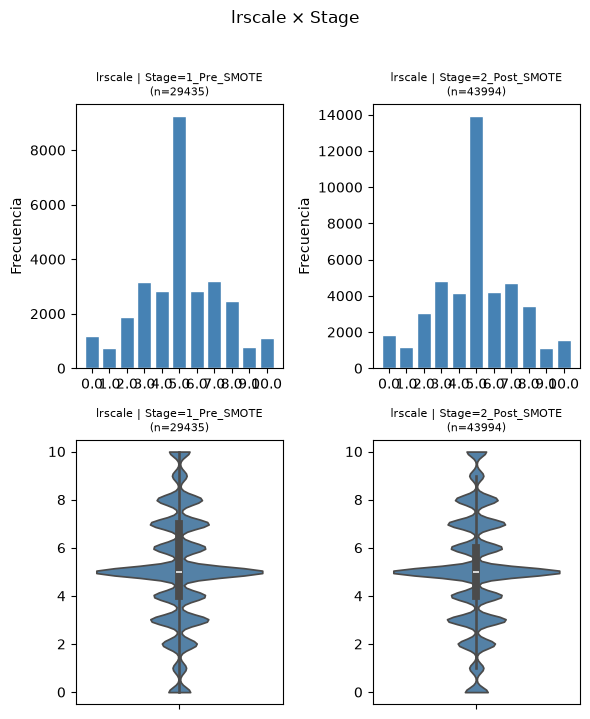

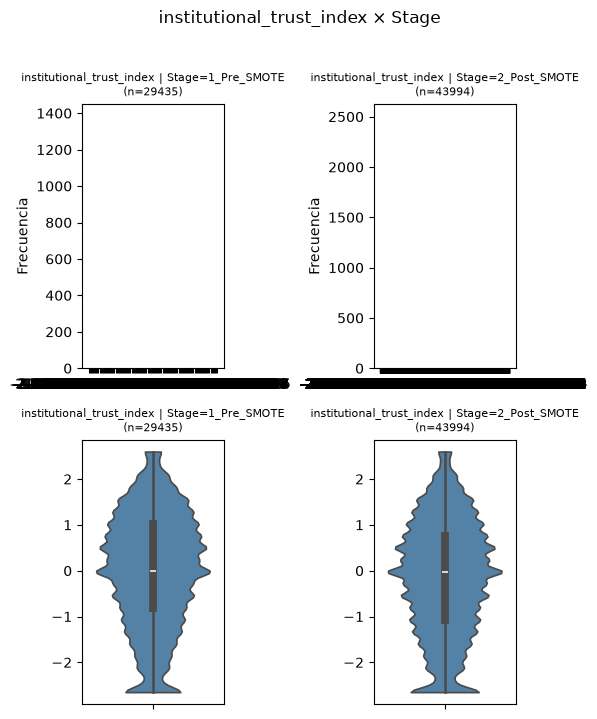

In [24]:
#Lets prepare the data, converting again the split function(series data) in to dataframe. Making 2 different study blocks, pre Smote and post Smote.
df_pre = X_train_final[["lrscale", "institutional_trust_index"]].copy()
df_pre["Stage"] = "1_Pre_SMOTE"

df_post = X_train_res[["lrscale", "institutional_trust_index"]].copy()
df_post["Stage"] = "2_Post_SMOTE"

df_smote_audit = pd.concat([df_pre, df_post], ignore_index=True)


multivariate_plot(df_smote_audit, study_col="lrscale", group_cols=["Stage"])


In [26]:
# The  bar plot from a continuous variable "institutional_trust_index" wont be painted, anyways,  we can observe how varies the statistical shape of our features using smote
# due balancing the multivariate classes, making more complex and capable our train data, to our future predictive model.
# In conclusion, this asymetric method of sinthetically create more samples of our minority classes, help us to capture better the intervariable relations we need to
# balance our data before applying machine learning.
# Lets store our data in an unified table in to our local sql server:
import os
import pandas as pd
import sqlalchemy
from dotenv import load_dotenv

load_dotenv()

# 1. prepare our train data block (Smote and rounded values)
df_train_sql = X_train_res.copy()
df_train_sql["happy_high"] = y_train_res.values
df_train_sql["split_set"] = "train"
# the original rows are not marked with "synthetic"
orig_countries = df81c.iloc[train_idx]["cntry"].tolist()
n_synth = len(df_train_sql) - len(orig_countries)
df_train_sql["cntry"] = orig_countries + ["SYNTHETIC"] * n_synth

# 2. Preparing test data block (100% non processed)
df_test_sql = X_test_final.copy()
df_test_sql["happy_high"] = y_test.values
df_test_sql["split_set"] = "test"
df_test_sql["cntry"] = df81c.iloc[test_idx]["cntry"].values

# 3. Unify all the data in one relational table.
df_split_master = pd.concat([df_train_sql, df_test_sql], ignore_index=True)

# 4. Upload to our local sql database, using our credentials on ".env" file.
db_uri = (
    f"postgresql+psycopg2://{os.getenv('PGUSER')}:{os.getenv('PGPASSWORD')}"
    f"@{os.getenv('PGHOST')}:{os.getenv('PGPORT')}/{os.getenv('PGDATABASE')}"
)
engine = sqlalchemy.create_engine(db_uri)

table_name = "ess_ex81_smote_split"
df_split_master.to_sql(table_name, con=engine, if_exists="replace", index=False)

print(f"✅ Tabla '{table_name}' persistida en PostgreSQL ({len(df_split_master)} filas).")

✅ Tabla 'ess_ex81_smote_split' persistida en PostgreSQL (52058 filas).


In [ ]:
#Our synthetic train data doesnt have cntry key value,it wasnt necesary saving the group variable value as an exercise.